# 03 · Forecasting hourly departures

**Task:** forecast departures per station per hour for the 40 busiest stations, early enough (the evening before) for vans to be planned.

**Validation:** a strict time-based split. Train on **Jun 2025 - Mar 2026**, test on **Apr - May 2026** (61 days, 4 bank holidays). A random split would leak information, because neighbouring hours and days are strongly correlated.

**Models, simplest first:** naive (same hour last week) → Poisson regression → random forest → LightGBM.

**Metrics:** MAE and RMSE (trips per station-hour) and **WAPE** = Σ|error| / Σ actual. WAPE is scale-free and easy to explain: "on average the forecast is off by X% of the trips that happened".

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
from plotting import set_style, save, SERIES, INK, INK_2, NEUTRAL, BLUE_RAMP
set_style()
import time, shap, lightgbm as lgb
import models as M
from features import FEATURES, TARGET
from rebalancing import assign_window
df = pd.read_parquet('../data/processed/features.parquet')
train, test = M.split(df)
print(f"train: {train['hour_ts'].min():%d %b %Y} - {train['hour_ts'].max():%d %b %Y}  ({len(train):,} rows)")
print(f"test:  {test['hour_ts'].min():%d %b %Y} - {test['hour_ts'].max():%d %b %Y}  ({len(test):,} rows)")
print('Features:', FEATURES)

train: 08 Jun 2025 - 31 Mar 2026  (283,200 rows)
test:  01 Apr 2026 - 31 May 2026  (58,560 rows)
Features: ['hour', 'dow', 'month', 'is_weekend', 'is_bank_holiday', 'is_school_holiday', 'temperature', 'precipitation', 'wind_speed', 'lag_24', 'lag_48', 'lag_168', 'same_hour_mean_7d', 'roll_7d_mean', 'nb_docks', 'lat', 'lon', 'station_code']


### Feature notes
* **Lags are all >= 24 h** (`lag_24` = same hour yesterday, `lag_168` = same hour last week, `same_hour_mean_7d`, `roll_7d_mean` = mean hourly demand over the 7 days to yesterday). This means a forecast for tomorrow can be made tonight.
* **Weather:** observed hourly weather is used as a stand-in for a day-ahead weather forecast. Real forecasts are less accurate, so the test scores are slightly optimistic about weather-sensitive hours.
* **Station identity** goes in as a categorical code, plus capacity and coordinates.
* **Humidity was deliberately removed.** In a first version it acted as a proxy for "wet day" and absorbed most of the rain signal. That model's rain effect was only about −10% and didn't increase with heavier rain. Dropping humidity left accuracy unchanged (WAPE 45.0% → 44.9%) and gave a rain effect that is monotone and agrees with the EDA, which is what an operations manager needs to trust it.
* The **5 Aug 2025 outage** has a masked target, so it is excluded from training. Lags that point into it are filled with the station's 7-day same-hour mean.

In [2]:
preds = test[['station_id', 'display_name', 'hour_ts', 'date', 'hour', 'dow', 'is_weekend', 'is_bank_holiday',
              'is_school_holiday', 'temperature', 'precipitation', 'nb_docks', 'arrivals', TARGET]].copy()
timings = {}
preds['naive'] = M.naive_forecast(test)

t = time.time(); pois = M.fit_poisson(train); preds['poisson'] = M.predict_poisson(pois, test); timings['poisson'] = time.time() - t
t = time.time(); rf = M.fit_random_forest(train, n_estimators=200); preds['random_forest'] = rf.predict(test[FEATURES]); timings['random_forest'] = time.time() - t
t = time.time(); gbm = M.fit_lightgbm(train); preds['lightgbm'] = gbm.predict(test[FEATURES]); timings['lightgbm'] = time.time() - t
print('LightGBM early-stopped at', gbm.best_iteration_probe, 'rounds')

LightGBM early-stopped at 1243 rounds


## 1. Accuracy

In [3]:
MODELS = ['naive', 'poisson', 'random_forest', 'lightgbm']
LABELS = {'naive': 'Naive (last week)', 'poisson': 'Poisson regression', 'random_forest': 'Random forest', 'lightgbm': 'LightGBM'}
hourly = pd.DataFrame({LABELS[m]: M.score(preds[TARGET], preds[m]) for m in MODELS}).T

# Planning level: vans are scheduled per time window, so also score station x day x window totals
preds['window'] = assign_window(preds['hour'])
win = preds.dropna(subset=['window']).groupby(['station_id', 'date', 'window'])[[TARGET] + MODELS].sum()
window = pd.DataFrame({LABELS[m]: M.score(win[TARGET], win[m]) for m in MODELS}).T

metrics = hourly.add_prefix('hourly_').join(window.add_prefix('window_'))
base = metrics.loc['Naive (last week)', 'hourly_WAPE']
metrics['WAPE_improvement_vs_naive'] = 1 - metrics['hourly_WAPE'] / base
metrics.to_csv('../reports/model_metrics.csv')
metrics.style.format({c: '{:.3f}' for c in metrics.columns if 'WAPE' not in c} | {c: '{:.1%}' for c in metrics.columns if 'WAPE' in c})

,hourly_MAE,hourly_RMSE,hourly_WAPE,window_MAE,window_RMSE,window_WAPE,WAPE_improvement_vs_naive
Naive (last week),2.322,4.359,61.8%,6.736,12.157,38.0%,0.0%
Poisson regression,1.919,3.432,51.1%,5.664,9.660,31.9%,17.3%
Random forest,1.813,3.282,48.2%,5.036,8.816,28.4%,21.9%
LightGBM,1.690,2.973,45.0%,4.492,7.463,25.3%,27.2%


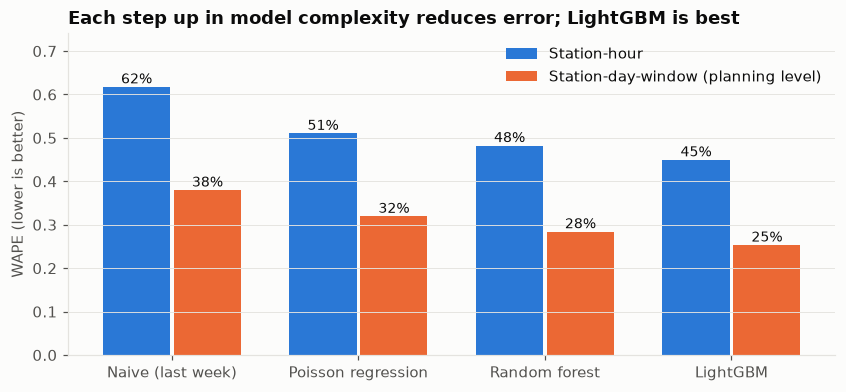

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(MODELS)); w = 0.36
b1 = ax.bar(x - w/2 - 0.01, metrics['hourly_WAPE'], w, color=SERIES[0], label='Station-hour')
b2 = ax.bar(x + w/2 + 0.01, metrics['window_WAPE'], w, color=SERIES[1], label='Station-day-window (planning level)')
for bars in (b1, b2):
    for b in bars: ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.008, f'{b.get_height():.0%}', ha='center', fontsize=9, color=INK)
ax.set_xticks(x, [LABELS[m] for m in MODELS]); ax.set_ylabel('WAPE (lower is better)'); ax.grid(axis='x', visible=False)
ax.set_title('Each step up in model complexity reduces error; LightGBM is best'); ax.legend(loc='upper right')
ax.set_ylim(0, metrics['hourly_WAPE'].max() * 1.2)
save(fig, '03_model_comparison');

Station-hour WAPE looks high in absolute terms because the counts are small: the median station-hour has only a few trips, so ±1 trip is a large percentage. At the **planning level** (total departures per station per window, which is what a van schedule uses), errors are much smaller.

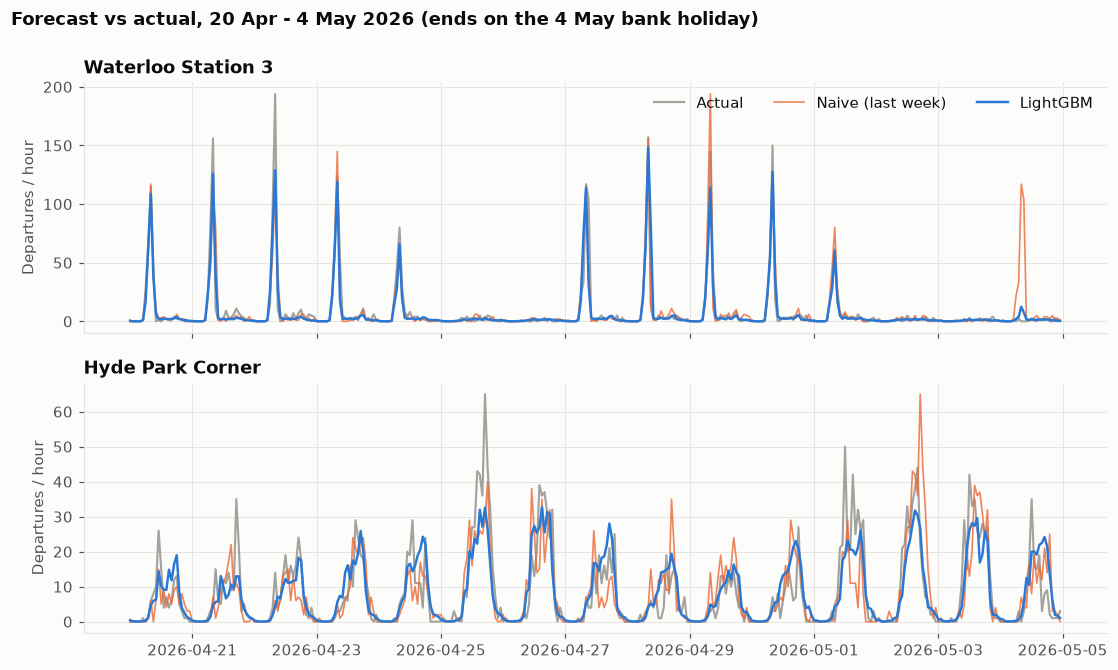

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
span = (preds['hour_ts'] >= '2026-04-20') & (preds['hour_ts'] < '2026-05-05')
for ax, name in zip(axes, ['Waterloo Station 3, Waterloo', 'Hyde Park Corner, Hyde Park']):
    s = preds[span & (preds['display_name'] == name)]
    ax.plot(s['hour_ts'], s[TARGET], color=NEUTRAL, lw=1.4, label='Actual')
    ax.plot(s['hour_ts'], s['naive'], color=SERIES[1], lw=1.1, alpha=0.8, label='Naive (last week)')
    ax.plot(s['hour_ts'], s['lightgbm'], color=SERIES[0], lw=1.6, label='LightGBM')
    ax.set_title(name.split(',')[0]); ax.set_ylabel('Departures / hour')
axes[0].legend(loc='upper right', ncol=3)
fig.suptitle('Forecast vs actual, 20 Apr - 4 May 2026 (ends on the 4 May bank holiday)', x=0.07, ha='left', fontweight='bold')
save(fig, '03_forecast_vs_actual');

## 2. Where the model fails

In [6]:
seg = M.segment_errors(preds, MODELS).set_index('segment')
seg.columns = ['hours', 'actual_mean'] + [LABELS[m] for m in MODELS]
seg.style.format({'actual_mean': '{:.1f}'} | {LABELS[m]: '{:.1%}' for m in MODELS})

,hours,actual_mean,Naive (last week),Poisson regression,Random forest,LightGBM
segment,,,,,,
All hours,58560,3.8,61.8%,51.1%,48.2%,45.0%
Weekday,41280,4.0,58.9%,47.9%,45.8%,42.4%
Weekend,17280,3.1,70.8%,61.1%,55.9%,53.2%
Bank holiday,3840,2.7,116.9%,85.7%,89.9%,61.9%
Weekday AM peak (07-09),5160,7.4,51.5%,41.3%,39.6%,34.6%
Weekday PM peak (16-18),5160,9.9,47.9%,38.4%,35.7%,33.0%
Dry hour,52280,3.8,61.1%,50.8%,48.0%,44.8%
Rain > 1 mm/h,280,5.5,68.5%,45.2%,43.7%,41.9%
Warm (>= 22C),6680,5.8,58.4%,49.3%,46.0%,42.5%


In [7]:
daily = preds.groupby('date')[[TARGET] + MODELS].sum()
daily['lgb_error_pct'] = (daily['lightgbm'] - daily[TARGET]) / daily[TARGET]
wx = preds.groupby('date').agg(rain_mm=('precipitation', 'sum'), max_temp=('temperature', 'max'),
                              bank_holiday=('is_bank_holiday', 'max'), dow=('dow', 'first'))
worst = daily.join(wx).reindex(daily['lgb_error_pct'].abs().sort_values(ascending=False).index).head(10)
worst['day'] = pd.to_datetime(worst.index).strftime('%a %d %b')
worst[['day', TARGET, 'lightgbm', 'naive', 'lgb_error_pct', 'rain_mm', 'max_temp', 'bank_holiday']].round(1)

,day,departures,lightgbm,naive,lgb_error_pct,rain_mm,max_temp,bank_holiday
date,,,,,,,,
2026-04-06,Mon 06 Apr,2681.0,2098.3,3354.0,-0.2,0.0,14.9,1
2026-04-22,Wed 22 Apr,5076.0,4070.6,3709.0,-0.2,0.0,16.5,0
2026-05-10,Sun 10 May,2112.0,2527.9,2917.0,0.2,12.0,13.6,0
2026-04-25,Sat 25 Apr,3768.0,3091.0,3121.0,-0.2,0.0,21.6,0
2026-04-24,Fri 24 Apr,4291.0,3601.6,3317.0,-0.2,0.0,19.2,0
2026-04-03,Fri 03 Apr,1953.0,2212.7,2516.0,0.1,60.0,16.0,1
2026-04-21,Tue 21 Apr,4481.0,3919.1,3905.0,-0.1,0.0,14.1,0
2026-04-10,Fri 10 Apr,3158.0,2819.2,1953.0,-0.1,0.0,12.9,0
2026-04-26,Sun 26 Apr,3211.0,2873.2,2869.0,-0.1,0.0,19.5,0


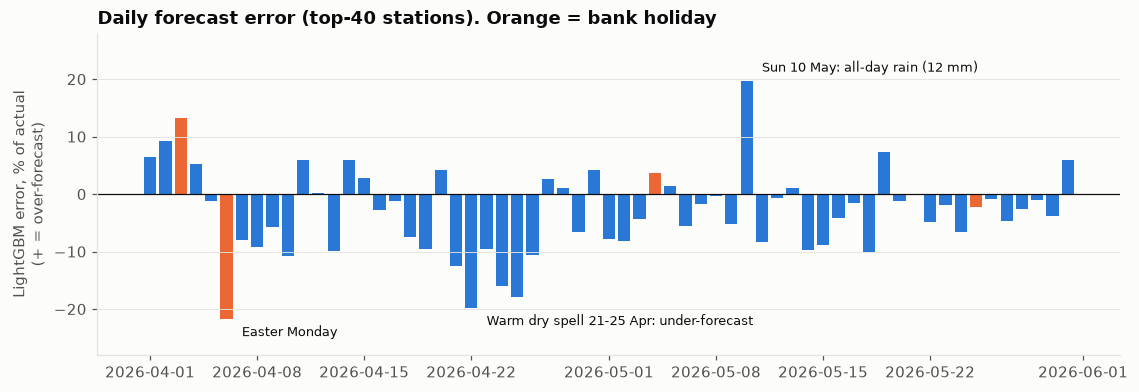

In [8]:
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.axhline(0, color=INK, lw=0.8)
colors = np.where(daily.join(wx)['bank_holiday'] == 1, SERIES[1], SERIES[0])
ax.bar(pd.to_datetime(daily.index), daily['lgb_error_pct'] * 100, color=colors, width=0.8)
notes = {'2026-05-10': 'Sun 10 May: all-day rain (12 mm)', '2026-04-06': 'Easter Monday', '2026-04-22': 'Warm dry spell 21-25 Apr: under-forecast'}
for d, lab in notes.items():
    v = daily.loc[pd.Timestamp(d), 'lgb_error_pct'] * 100
    ax.annotate(lab, (pd.Timestamp(d), v), xytext=(10, 4 if v > 0 else -4), textcoords='offset points', fontsize=8.5, color=INK,
                va='bottom' if v > 0 else 'top')
ax.set_ylim(-28, 28)
ax.set_ylabel('LightGBM error, % of actual\n(+ = over-forecast)'); ax.grid(axis='x', visible=False)
ax.set_title('Daily forecast error (top-40 stations). Orange = bank holiday')
save(fig, '03_daily_error');

In [9]:
bh = daily.join(wx)
bh = bh[bh['bank_holiday'] == 1][[TARGET, 'naive', 'lightgbm']]
bh.index = pd.to_datetime(bh.index).strftime('%a %d %b'); bh['lgb_err'] = bh['lightgbm'] / bh[TARGET] - 1; bh['naive_err'] = bh['naive'] / bh[TARGET] - 1
bh.round(2)

,departures,naive,lightgbm,lgb_err,naive_err
date,,,,,
Fri 03 Apr,1953.0,2516.0,2212.73,0.13,0.29
Mon 06 Apr,2681.0,3354.0,2098.28,-0.22,0.25
Mon 04 May,2434.0,4139.0,2522.85,0.04,0.70
Mon 25 May,3234.0,3856.0,3162.76,-0.02,0.19


## 3. Explainability

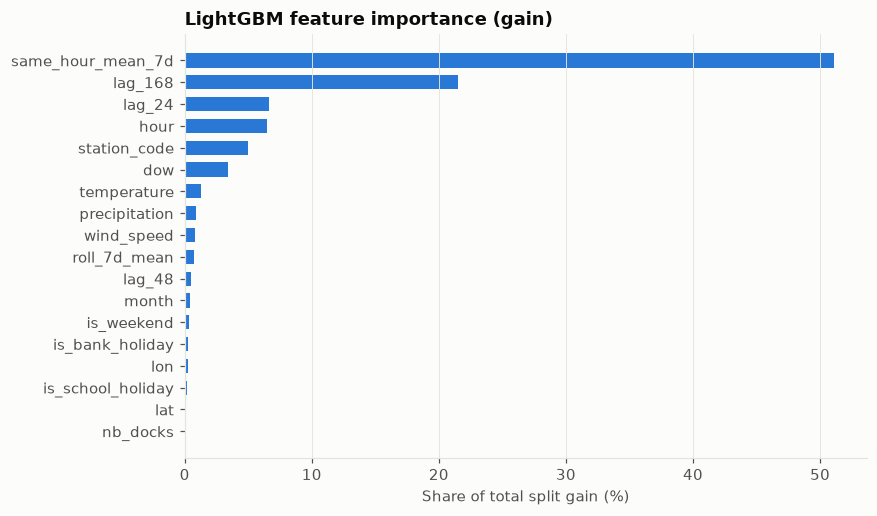

In [10]:
imp = pd.Series(gbm.feature_importance('gain'), index=FEATURES).sort_values()
imp = imp / imp.sum()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values * 100, color=SERIES[0], height=0.65)
ax.set_xlabel('Share of total split gain (%)'); ax.set_title('LightGBM feature importance (gain)'); ax.grid(axis='y', visible=False)
save(fig, '03_feature_importance');

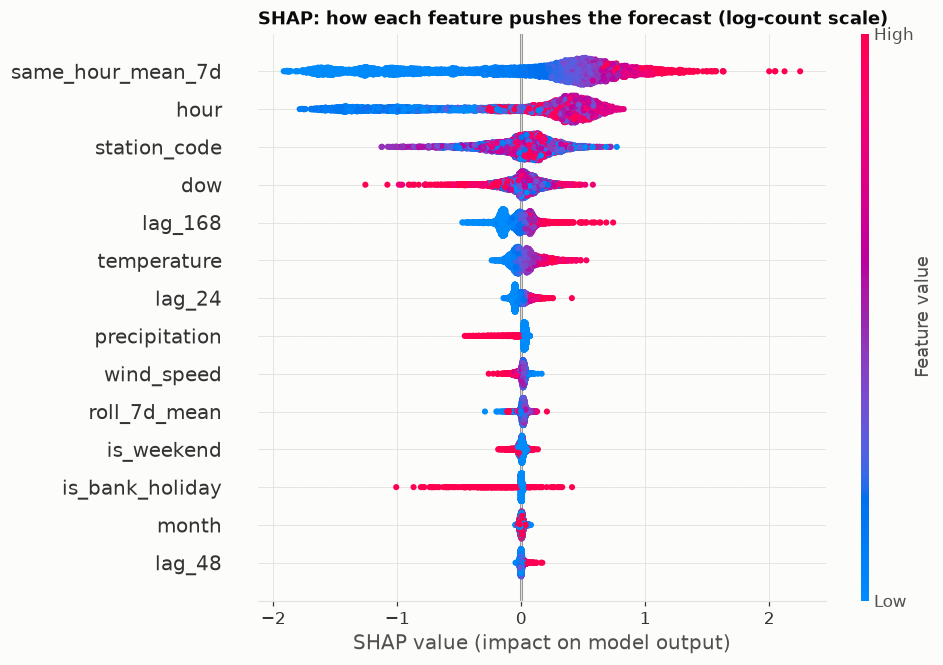

In [11]:
sample = test.sample(5000, random_state=1)
explainer = shap.TreeExplainer(gbm)
sv = explainer.shap_values(sample[FEATURES])
plt.figure()
shap.summary_plot(sv, sample[FEATURES], show=False, max_display=14, plot_size=(9, 6))
plt.title('SHAP: how each feature pushes the forecast (log-count scale)', loc='left', fontweight='bold')
save(plt.gcf(), '03_shap_summary');

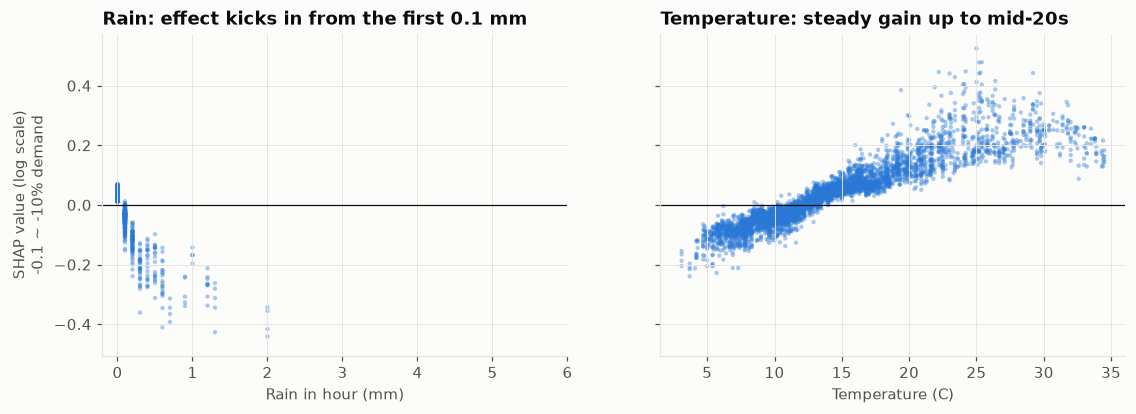

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, f, lab in zip(axes, ['precipitation', 'temperature'], ['Rain in hour (mm)', 'Temperature (C)']):
    i = FEATURES.index(f)
    ax.scatter(sample[f], sv[:, i], s=8, alpha=0.4, color=SERIES[0], edgecolor='none')
    ax.axhline(0, color=INK, lw=0.8); ax.set_xlabel(lab)
axes[0].set_xlim(-0.2, 6); axes[0].set_ylabel('SHAP value (log scale)\n-0.1 ~ -10% demand')
axes[0].set_title('Rain: effect kicks in from the first 0.1 mm'); axes[1].set_title('Temperature: steady gain up to mid-20s')
save(fig, '03_shap_weather');

### "Rain above X mm cuts predicted demand by about Y%"

SHAP values sit on the model's log scale, so the cleanest business statement comes from a **counterfactual**: take every daytime test hour (07:00-20:59), force rainfall to a fixed value, and compare average predicted demand with the same hours forced dry. Rain is changed for a single hour at a time, so lingering effects of an all-day downpour (e.g. wet roads after the rain stops) aren't captured. Treat these as lower-end estimates.

In [13]:
day = test[test['hour'].between(7, 20)].copy()
base_pred = gbm.predict(day[FEATURES].assign(precipitation=0.0)).sum()
rows = []
for mm in [0.2, 0.5, 1, 2, 4]:
    p = gbm.predict(day[FEATURES].assign(precipitation=float(mm))).sum()
    rows.append({'rain_mm_per_hour': mm, 'change_vs_dry': p / base_pred - 1})
rain_cf = pd.DataFrame(rows); rain_cf.to_csv('../reports/rain_counterfactual.csv', index=False)
temp_rows = []
for t in [5, 10, 15, 20, 25]:
    temp_rows.append({'temperature_C': t, 'pred': gbm.predict(day[FEATURES].assign(temperature=float(t))).sum()})
temp_cf = pd.DataFrame(temp_rows); temp_cf['vs_15C'] = temp_cf['pred'] / temp_cf.loc[temp_cf['temperature_C'] == 15, 'pred'].iloc[0] - 1
display(rain_cf.style.format({'change_vs_dry': '{:+.1%}'})); display(temp_cf[['temperature_C', 'vs_15C']].style.format({'vs_15C': '{:+.1%}'}))
r1 = rain_cf.set_index('rain_mm_per_hour')['change_vs_dry']
print(f"=> Rain of 1 mm/h cuts predicted daytime demand by about {-r1[1]:.0%}; 2 mm/h by about {-r1[2]:.0%}.")

,rain_mm_per_hour,change_vs_dry
0,0.200000,-16.4%
1,0.500000,-22.9%
2,1.000000,-24.6%
3,2.000000,-26.0%
4,4.000000,-29.0%


,temperature_C,vs_15C
0,5,-13.9%
1,10,-9.9%
2,15,+0.0%
3,20,+5.2%
4,25,+8.8%


=> Rain of 1 mm/h cuts predicted daytime demand by about 25%; 2 mm/h by about 26%.


In [14]:
import joblib, pathlib
pathlib.Path('../models').mkdir(exist_ok=True)
gbm.save_model('../models/lightgbm_departures.txt')
preds.to_parquet('../data/processed/test_predictions.parquet', index=False)
print('saved predictions', preds.shape)

saved predictions (58560, 19)
